In [1]:
import sys
import os
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)
import json
import torch
import numpy as np
import pandas as pd
import matplotlib
# 弹出绘图窗口
# matplotlib.use('TkAgg')
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable

from model.CSU_EI import CSUEI
from model.tokenizer import build_tokenizer
from data_provider.dataset import *


config_path = os.path.join(PROJECT_ROOT, 'results/CSUEI_2025-01-09_204745/config_2025-01-09_204745.json')
model_path = os.path.join(PROJECT_ROOT, 'results/CSUEI_2025-01-09_204745/checkpoints/trained_model_6+6_16epoc+1024+3e4_2025-01-09_204745.pth')

with open(config_path, 'r') as f:
        config_json = json.loads(f.read())
config_json['roberta_tokenizer_path'] = os.path.join(PROJECT_ROOT,  config_json['roberta_tokenizer_path'])
model_dict = torch.load(model_path, map_location=config_json["device"])
model = CSUEI(**config_json["model_config"])
model.load_state_dict(model_dict)
tokenizer = build_tokenizer(config_json['roberta_tokenizer_path'])
model.to(config_json["device"])

Project root: d:\CSU-EI_to_crx\code+paper\code\github_version


d:\Anaconda\envs\csu-ei\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CSUEI(
  (Smiles_model): SmilesModel(
    (smiles_model): RobertaModel(
      (embeddings): RobertaEmbeddings(
        (word_embeddings): Embedding(181, 768, padding_idx=1)
        (position_embeddings): Embedding(505, 768, padding_idx=1)
        (token_type_embeddings): Embedding(1, 768)
        (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (encoder): RobertaEncoder(
        (layer): ModuleList(
          (0-5): 6 x RobertaLayer(
            (attention): RobertaAttention(
              (self): RobertaSelfAttention(
                (query): Linear(in_features=768, out_features=768, bias=True)
                (key): Linear(in_features=768, out_features=768, bias=True)
                (value): Linear(in_features=768, out_features=768, bias=True)
                (dropout): Dropout(p=0.1, inplace=False)
              )
              (output): RobertaSelfOutput(
                (dense): Linear(in_features=76

## test_plot.py

['CCCCCCOc1ccc(OCCCCCC)cc1' 'COc1cc(Br)cc(OC)c1' 'COC(=O)CCCCCBr'
 'COc1c(Br)cccc1C(C)=O' 'CC(C)(C)c1cc(Br)cc(Br)c1'
 'Brc1ccc(-c2ccc(Br)cn2)nc1' 'COc1cc(-c2c(OC)cccc2OC)cc(OC)c1OC'
 'CC(C)(C)c1cc(C=O)c(O)c(C=O)c1'
 'c1cc(-c2cc(-c3ccncc3)nc(-c3ccncc3)c2)ccn1'
 'BrCCCCCCCCCCCCOc1cc(Br)cc(Br)c1']


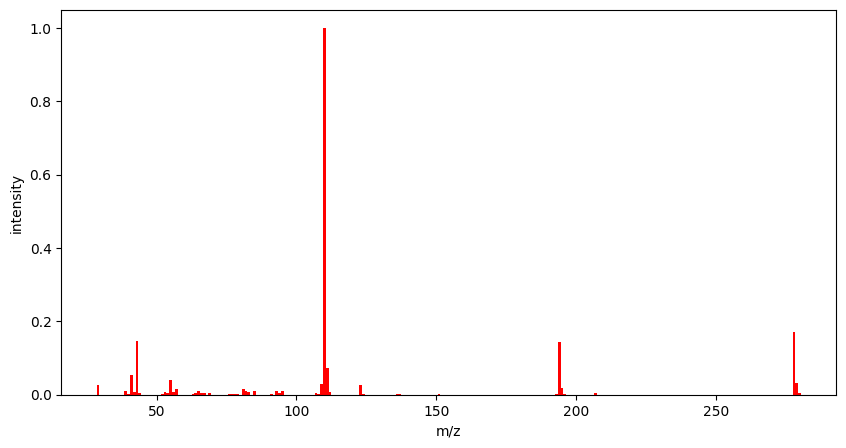

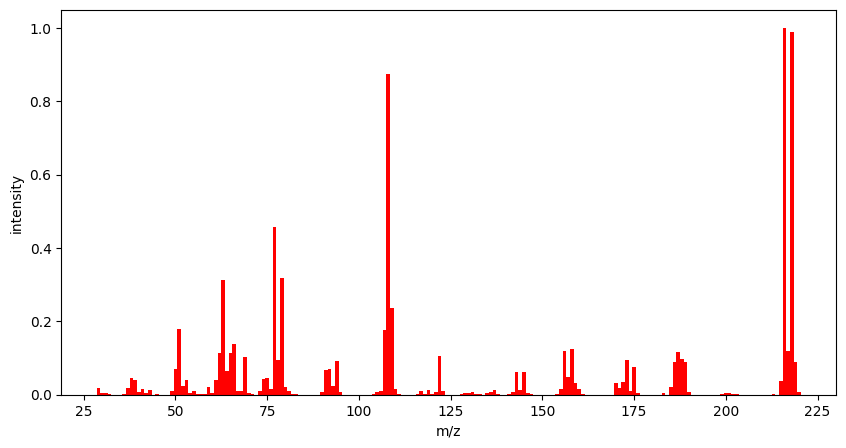

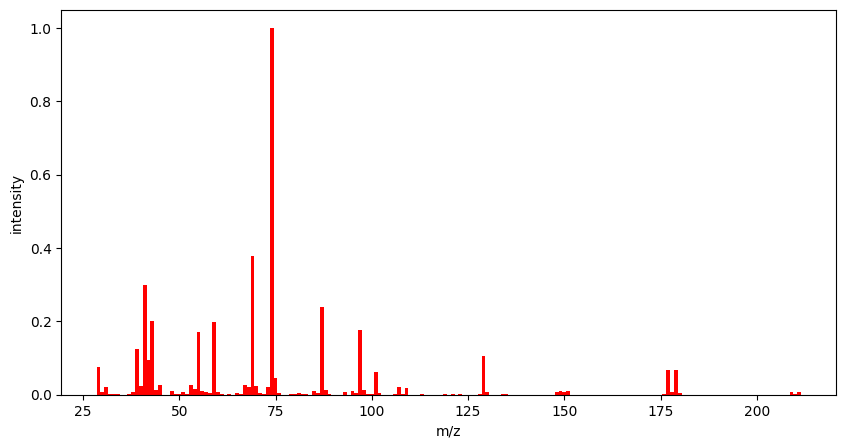

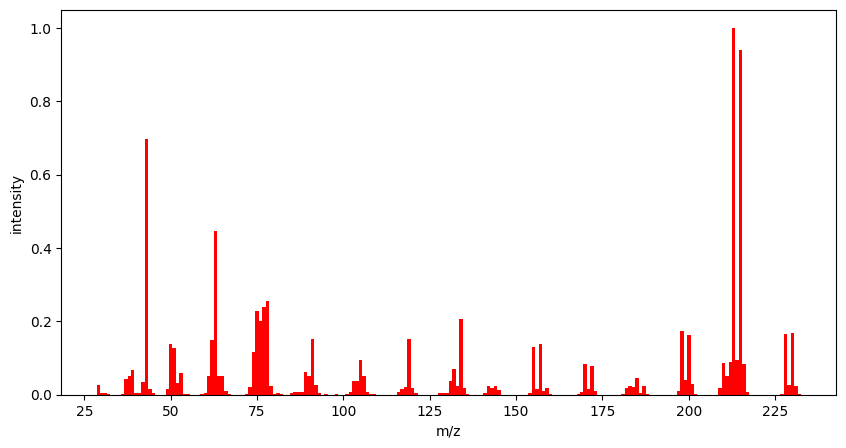

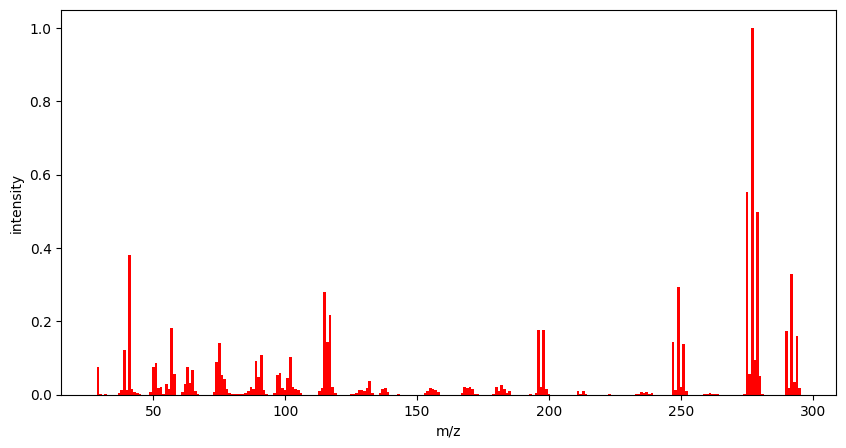

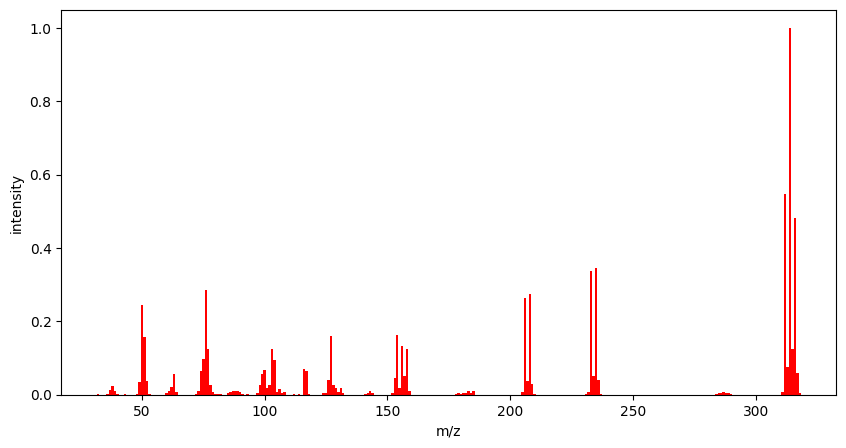

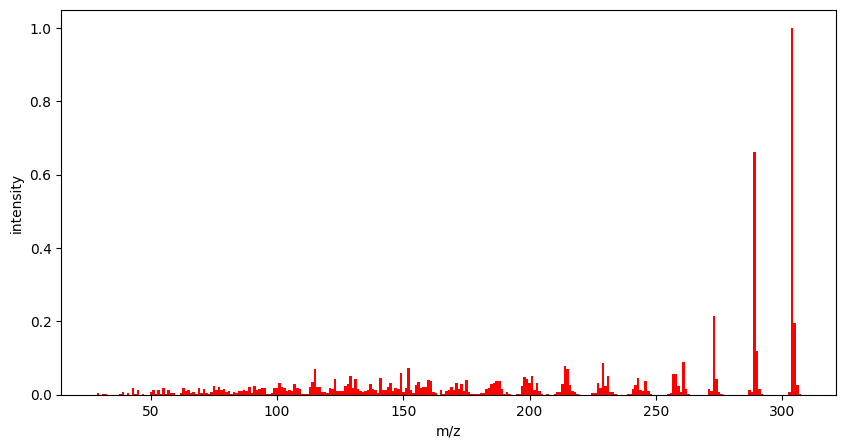

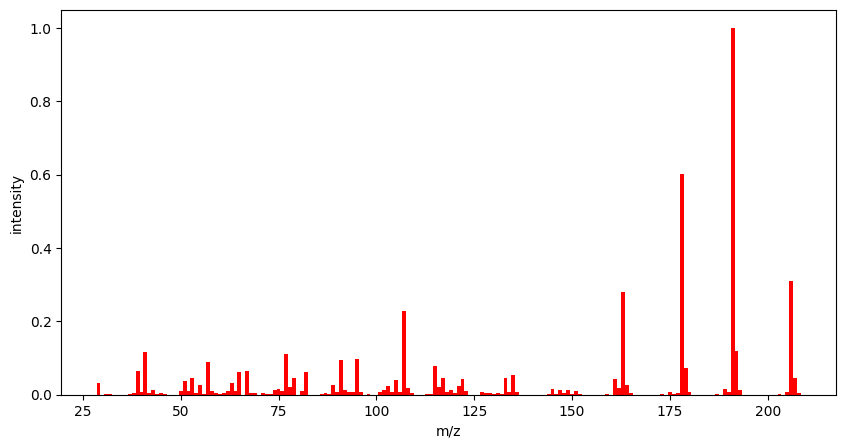

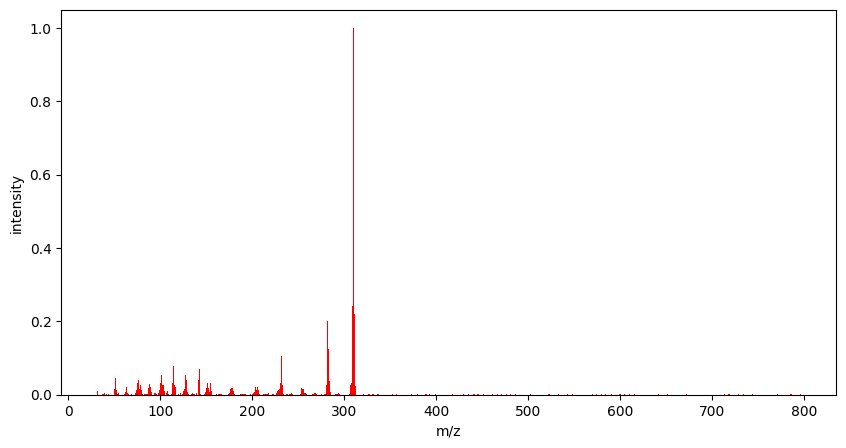

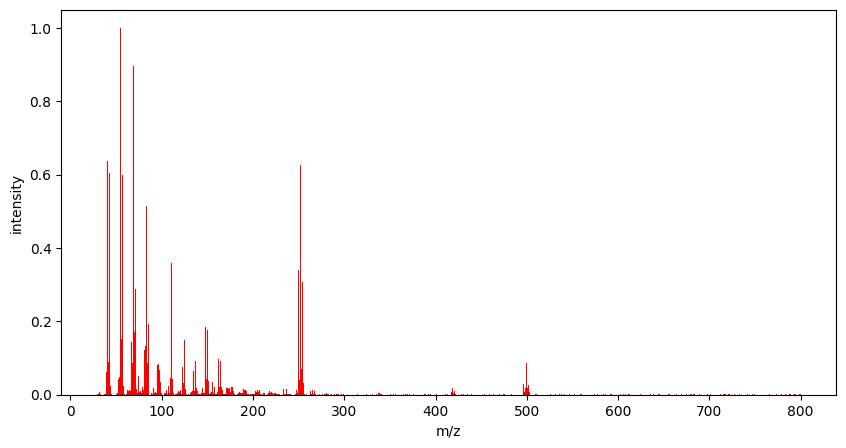

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("../data/External_Test_Set/Gen_10/10.csv")
SMILES = df["smiles"].values
print(SMILES)
EIMS = df["spectra"].values

import matplotlib.pyplot as plt
import ast

for peaks_data in EIMS:
    if isinstance(peaks_data, str):
        peaks_data = ast.literal_eval(peaks_data)
    peaks = np.array(peaks_data, dtype=np.float32)
    mz = peaks[:, 0]
    mz_max = mz.max()
    intensity = peaks[:, 1]
    intensity = intensity / intensity.max()
    plt.figure(figsize=(10, 5))
    # 绘制质谱图，横坐标为m/z，纵坐标为intensity，bar的宽度为0.5, 颜色为红色
    plt.bar(mz, intensity, width=1, color='red')
    plt.xlabel("m/z")
    plt.ylabel("intensity")
    plt.show()
        

/home/jialong/miniconda3/envs/csu-ei/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Plotting loss curve to /home/jialong/github_version/results/CSUEI_2025-01-09_204745/loss_record/data/plots/loss_record_6+6_16epoc+1024+3e4_2025-01-09_204745.png...
Done.


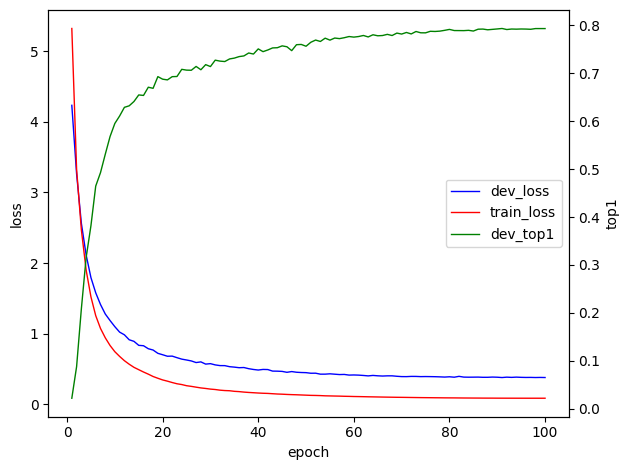

In [1]:
import torch
import os
import sys

# Ensure project root is in path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from analyzer.core import plot_loss_curve

# 1. 加载数据
file_path = '/home/jialong/github_version/results/CSUEI_2025-01-09_204745/loss_record/data/loss_record_6+6_16epoc+1024+3e4_2025-01-09_204745.pth'

# 加载 .pth 文件
data = torch.load(file_path, map_location='cpu')

# 解析 loss_record
if isinstance(data, tuple):
    loss_record = data[0]
else:
    loss_record = data

# 2. 定义保存路径 (在当前目录下创建 plots 文件夹)
dir_name = os.path.dirname(file_path)
plots_dir = os.path.join(dir_name, 'plots')
os.makedirs(plots_dir, exist_ok=True)

file_name = os.path.basename(file_path).replace('.pth', '.png')
fig_save_path = os.path.join(plots_dir, file_name)

# 3. 调用绘图函数
print(f"Plotting loss curve to {fig_save_path}...")
plot_loss_curve(loss_record, fig_save_path)
print("Done.")

In [2]:
import torch
import os
from analyzer.core import *

# Call the function
file_path = '/home/jialong/github_version/results/CSUEI_smil6_smifd768_smih12_smiesaTrue_msl6_mse768_msh12_msesaTrue_rm1_2025-12-23_194718/loss_record/data/loss_record_2025-12-23_194718.pth'
df = convert_pth_to_csv(file_path)

Loading data from: /home/jialong/github_version/results/CSUEI_smil6_smifd768_smih12_smiesaTrue_msl6_mse768_msh12_msesaTrue_rm1_2025-12-23_194718/loss_record/data/loss_record_2025-12-23_194718.pth
CSV file saved to: /home/jialong/github_version/results/CSUEI_smil6_smifd768_smih12_smiesaTrue_msl6_mse768_msh12_msesaTrue_rm1_2025-12-23_194718/loss_record/data/loss_record_2025-12-23_194718.csv
Minimum Dev Loss: 1.147101 at epoch 47
Head of DataFrame:
   epoch  train_loss  dev_loss  dev_top1                  timestamp  \
0      1    6.361923  5.930391  0.001487 2025-12-23 19:57:02.904826   
1      2    5.181410  5.291849  0.005771 2025-12-23 20:03:32.793353   
2      3    4.429341  4.867165  0.013816 2025-12-23 20:10:23.098389   
3      4    3.851590  4.301907  0.045995 2025-12-23 20:17:13.246385   
4      5    3.368801  3.915653  0.074414 2025-12-23 20:24:07.411551   

   early_stop_cnt  
0               0  
1               0  
2               0  
3               0  
4               0  


In [2]:
import sys
import os
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, PROJECT_ROOT)
from analyzer.core import *

# Call the function
file_path = '/home/jialong/github_version/results/CSUEI_2025-01-09_204745/loss_record/data/loss_record_6+6_16epoc+1024+3e4_2025-01-09_204745.pth'
df = convert_pth_to_csv(file_path)



Loading data from: /home/jialong/github_version/results/CSUEI_2025-01-09_204745/loss_record/data/loss_record_6+6_16epoc+1024+3e4_2025-01-09_204745.pth
CSV file saved to: /home/jialong/github_version/results/CSUEI_2025-01-09_204745/loss_record/data/loss_record_6+6_16epoc+1024+3e4_2025-01-09_204745.csv
Minimum Dev Loss: 0.380308 at epoch 91
Head of DataFrame:
   epoch  train_loss  dev_loss  dev_top1                  timestamp  \
0      1    5.318506  4.231637  0.021861 2025-01-09 21:06:47.341873   
1      2    3.326317  3.261632  0.087793 2025-01-09 21:26:19.157570   
2      3    2.467345  2.560675  0.208814 2025-01-09 21:45:59.132247   
3      4    1.899676  2.113324  0.315845 2025-01-09 22:05:36.631190   
4      5    1.522035  1.793960  0.381952 2025-01-09 22:25:14.753674   

   early_stop_cnt  
0               0  
1               0  
2               0  
3               0  
4               0  


In [3]:
import sys
import os
import glob
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, PROJECT_ROOT)
from analyzer.core import *

# 1. 设置目标文件夹路径
target_dir = '/home/jialong/github_version/results/loss_record/'

# 2. 获取该目录下所有 .pth 文件
pth_files = glob.glob(os.path.join(target_dir, '*.pth'))

print(f"Found {len(pth_files)} .pth files in {target_dir}")

# 3. 批量转换
for file_path in pth_files:
    print(f"Converting: {os.path.basename(file_path)}")
    try:
        # 转换并保存为同名 csv (convert_pth_to_csv 默认会在同目录下生成 csv)
        df = convert_pth_to_csv(file_path)
    except Exception as e:
        print(f"Error converting {file_path}: {e}")

print("Batch conversion completed.")

Found 22 .pth files in /home/jialong/github_version/results/loss_record/
Converting: loss_record_6+6+512_2024-12-18_150848.pth
Loading data from: /home/jialong/github_version/results/loss_record/loss_record_6+6+512_2024-12-18_150848.pth
CSV file saved to: /home/jialong/github_version/results/loss_record/loss_record_6+6+512_2024-12-18_150848.csv
Minimum Dev Loss: 0.296336 at epoch 100
Head of DataFrame:
   epoch  train_loss  dev_loss  dev_top1                  timestamp  \
0      1    4.816515  4.011890  0.010930 2024-12-18 15:26:47.351891   
1      2    3.000892  3.064991  0.047831 2024-12-18 15:45:15.018199   
2      3    2.172108  2.378830  0.132039 2024-12-18 16:03:45.724505   
3      4    1.638986  1.956266  0.222805 2024-12-18 16:22:15.655623   
4      5    1.292200  1.625954  0.303078 2024-12-18 16:40:44.005823   

   early_stop_cnt  
0               0  
1               0  
2               0  
3               0  
4               0  
Converting: loss_record_8+1_20epoc+512_2024-12-